In [1]:
%load_ext autoreload
%autoreload 2

https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd

In [2]:
import os

import sparrow as sp

the value of the environment variable BASIC_DCT_BACKEND is not in ["JAX","SCIPY"]


In [3]:
path = "/Users/arnedf/VIB/DATA/visium" # pick a path where the zarr store will be saved
sdata=sp.datasets.visium_hd_example( bin_size=[ 2, 8, 16 ], output = os.path.join( path, "sdata_custom_binning_example.zarr" ) )

/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     The Zarr backing store has been changed from None the new file path:                                      
         /Users/arnedf/VIB/DATA/visium/sdata_custom_binning_example.zarr                                           


create a grid

In [11]:
size = 32
# take shape of grid equal to full h&e image
se = sdata[ "Visium_HD_Mouse_Small_Intestine_full_image" ][ "scale0" ][ "image" ]
sdata = sp.im.add_grid_labels_layer( sdata, shape = se.shape[1:], size=size, output_shapes_layer="square_shapes", output_labels_layer="square_labels", grid_type="square" )

2024-09-30 12:21:28,468 - sparrow.image._manager - WARNING - No dims parameter specified. Assuming order of dimension of provided array is ((c), (z), y, x)
2024-09-30 12:21:28,472 - sparrow.image._manager - INFO - Writing results to layer 'square_labels'


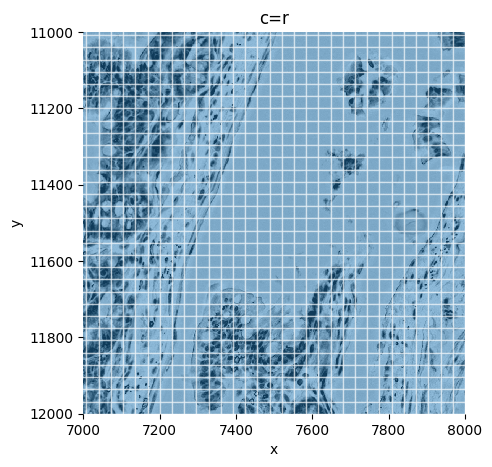

In [20]:
# lets plot the grid
sp.pl.plot_shapes( sdata,
                  img_layer="Visium_HD_Mouse_Small_Intestine_full_image",
                  shapes_layer="square_shapes", 
                  crd = [7000,8000,11000, 12000],
                  channel = "r",
                  figsize=(5,5)
                   )

In [21]:
sdata

SpatialData object, with associated Zarr store: /Users/arnedf/VIB/DATA/visium/sdata_custom_binning_example.zarr
├── Images
│     ├── 'Visium_HD_Mouse_Small_Intestine_full_image': DataTree[cyx] (3, 21943, 23618), (3, 10971, 11809), (3, 5485, 5904), (3, 2742, 2952), (3, 1371, 1476)
│     ├── 'Visium_HD_Mouse_Small_Intestine_hires_image': DataArray[cyx] (3, 5575, 6000)
│     └── 'Visium_HD_Mouse_Small_Intestine_lowres_image': DataArray[cyx] (3, 558, 600)
├── Labels
│     ├── 'Visium_HD_Mouse_Small_Intestine_square_002um_labels': DataArray[yx] (3285, 3191)
│     ├── 'Visium_HD_Mouse_Small_Intestine_square_008um_labels': DataArray[yx] (822, 799)
│     ├── 'Visium_HD_Mouse_Small_Intestine_square_016um_labels': DataArray[yx] (412, 400)
│     └── 'square_labels': DataArray[yx] (21943, 23618)
├── Shapes
│     ├── 'Visium_HD_Mouse_Small_Intestine_square_002um': GeoDataFrame shape: (5479660, 1) (2D shapes)
│     ├── 'Visium_HD_Mouse_Small_Intestine_square_008um': GeoDataFrame shape: (351817, 1) (

In [22]:
# now do a custom binning using the generated labels layer 'square_labels'.
# below step should be quite fast, 50-ish seconds on mac m2
sdata=sp.tb.bin_counts( 
    sdata,
    table_layer="square_002um",
    labels_layer="square_labels",
    output_layer="table_custom_bins",
    append = False,
    overwrite=True,
      )

2024-09-30 13:04:12,925 - sparrow.table._allocation - INFO - Calculating cell counts.
2024-09-30 13:04:32,241 - sparrow.table._allocation - INFO - 
 Number of spots per bin  Frequency
                       1        675
                       2       1284
                       3        728
                       4       1933
                       5        692
                       6        946
                       7        213
                       8       1795
                       9        340
                      10       1192
                      11        331
                      12       1838
                      13        469
                      14        990
                      15        936
                      16     100368
                      17       4915
                      18       5051
                      19       4955
                      20     118720
                      21       2896
                      22       2758
                      23

2024-09-30 13:07:18,342 - sparrow.plot._plot - WARNING - There are '285' cells in provided shapes_layer 'square_shapes' not found in 'sdata.tables[table_custom_bins]' (linked through 'cell_ID'), these cells will not be plotted.


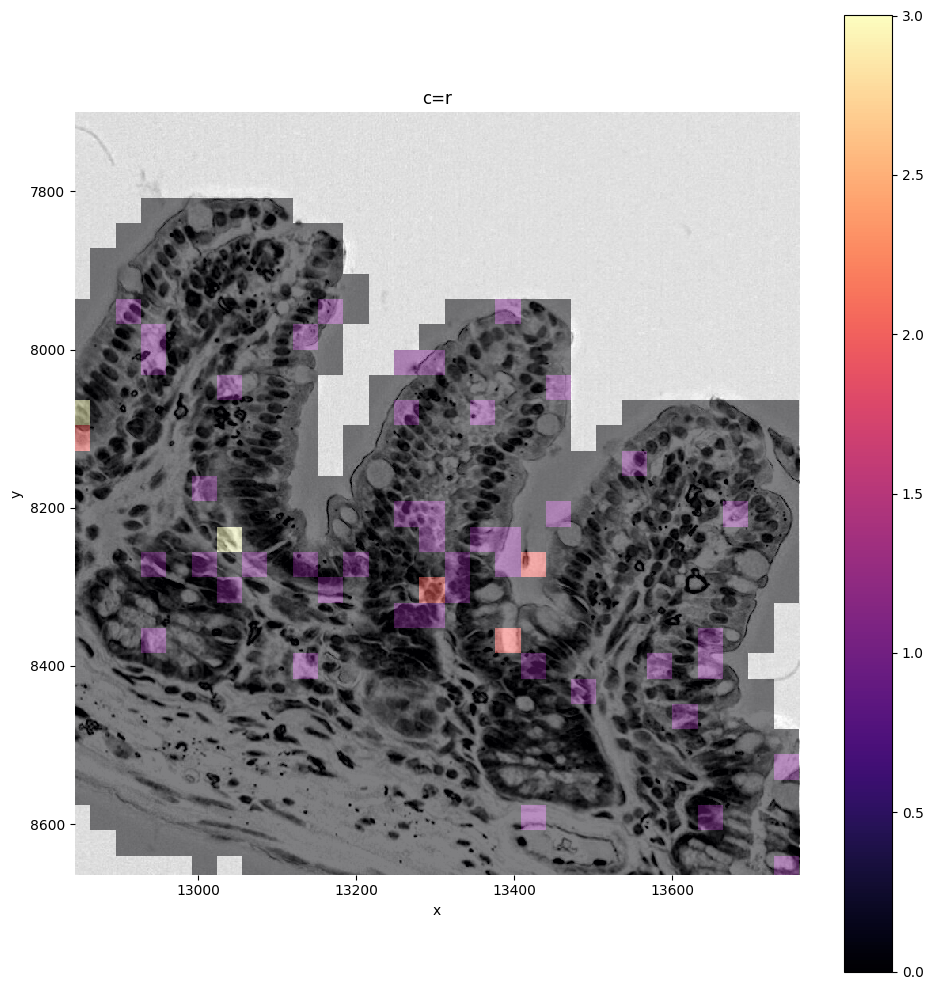

In [28]:
sp.pl.plot_shapes(
    sdata,
    img_layer = "Visium_HD_Mouse_Small_Intestine_full_image",
    shapes_layer="square_shapes",
    crd = [ 12844, 13760, 7700, 8664 ],
    channel="r",
    table_layer = "table_custom_bins",
    column="Lypla1",
    linewidth=0,
      )

2024-09-30 13:09:00,888 - sparrow.plot._plot - WARNING - There are '9421' cells in provided shapes_layer 'square_shapes' not found in 'sdata.tables[table_custom_bins]' (linked through 'cell_ID'), these cells will not be plotted.


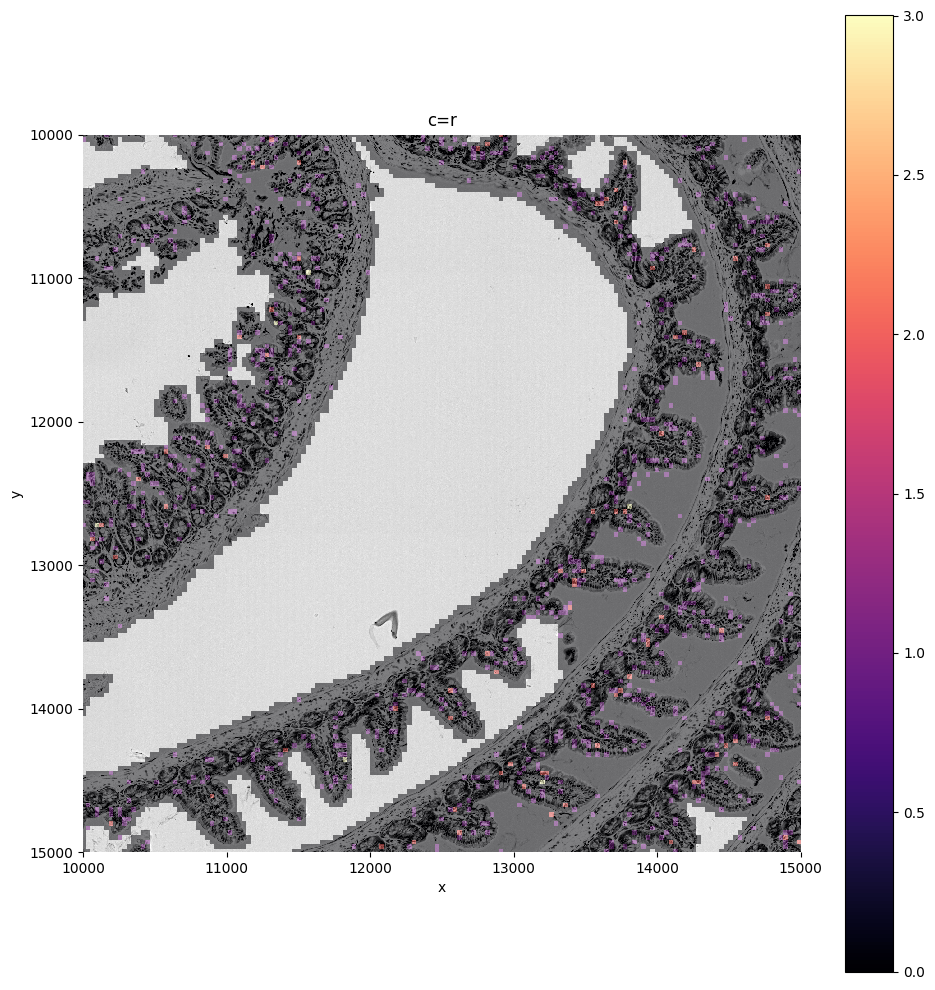

In [29]:
sp.pl.plot_shapes(
    sdata,
    img_layer = "Visium_HD_Mouse_Small_Intestine_full_image",
    shapes_layer="square_shapes", # shapes layer associated with our custom bin
    crd = [10000, 15000, 10000, 15000 ],
    channel="r",
    table_layer = "table_custom_bins",
    column="Lypla1",
    linewidth=0,
      )

In [30]:
import scanpy as sc

# you can then proceed doing normalization, and other processing steps using scanpy/squidpy etc...
adata_norm=sc.pp.normalize_total( sdata.tables[ "table_custom_bins" ] )

In [31]:
#import numpy as np

#np.where(sdata.tables[ "table_custom_bins" ].X[0].toarray() !=0 )

(array([0, 0, 0]), array([ 7337, 13546, 13963]))

In [32]:
#sdata.tables[ "table_custom_bins" ].X[0].toarray()[ :, 7337 ]

array([127.])

Now lets use a custom segmentation mask instead of a grid

2024-09-30 13:18:02,410 - sparrow.utils._io - WARNING - layer with name 'segmentation_boundaries' already exists. Overwriting...


plotting


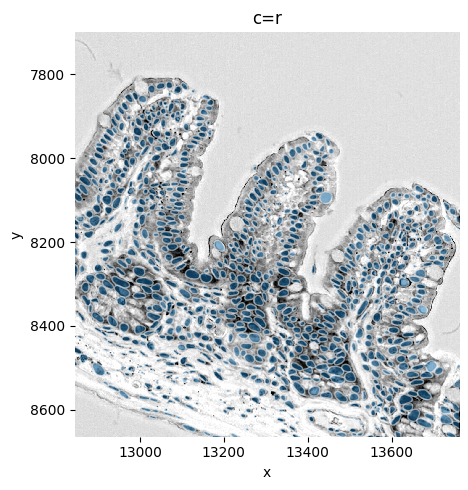

In [36]:
import geopandas as gpd

from sparrow.datasets.registry import get_registry

registry = get_registry()

# read in a mask, and add it to the spatialdata object ( obtained from visium hd tutorial)
# https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd

path_polygons = registry.fetch( "transcriptomics/visium_hd/mouse/masks.geojson" ) # custom segmentation of H&E

gdf = gpd.read_file(path_polygons)
gdf.index=gdf.index +1

sdata=sp.sh.add_shapes_layer(
    sdata,
    input=gdf,
    output_layer="segmentation_boundaries",
    overwrite=True,
      )

sp.pl.plot_shapes(
    sdata, 
    img_layer="Visium_HD_Mouse_Small_Intestine_full_image",
    shapes_layer="segmentation_boundaries",
    crd =[ 12844, 13760, 7700, 8664 ],
    figsize=(5,5) ,
    channel="r",
      )

In [39]:
labels_layer = "segmentation_mask"
sdata=sp.im.add_labels_layer_from_shapes_layer( sdata, shapes_layer="segmentation_boundaries", output_layer=labels_layer, overwrite=True )

2024-09-30 13:26:01,959 - sparrow.image._manager - WARNING - No dims parameter specified. Assuming order of dimension of provided array is ((c), (z), y, x)
2024-09-30 13:26:01,964 - sparrow.image._manager - INFO - Writing results to layer 'segmentation_mask'
2024-09-30 13:26:35,822 - sparrow.utils._io - WARNING - layer with name 'segmentation_mask' already exists. Overwriting...


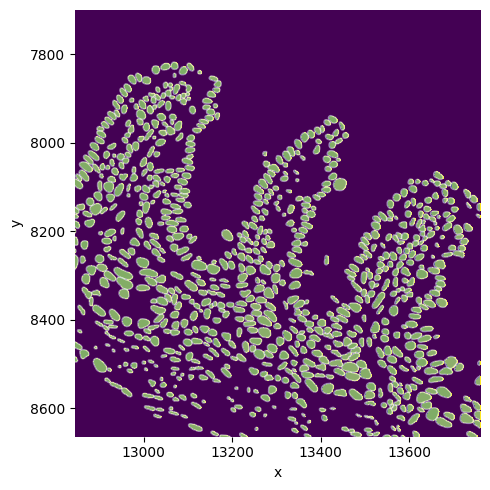

In [40]:
# sanity plot
sp.pl.plot_shapes(
    sdata, 
    labels_layer="segmentation_mask",
    shapes_layer="segmentation_boundaries",
    crd =[ 12844, 13760, 7700, 8664 ],
    figsize=(5,5),
    channel="r",
      )

In [49]:
# bin barcodes to the segmentation masks
sdata=sp.tb.bin_counts( 
    sdata,
    table_layer="square_002um",
    labels_layer="segmentation_mask",
    output_layer="table_custom_segmentation",
    append = False,
    overwrite=True,
      )

2024-09-30 13:41:32,053 - sparrow.table._allocation - INFO - Calculating cell counts.
2024-09-30 13:42:48,603 - sparrow.table._allocation - INFO - 
 Number of spots per bin  Frequency
                       1      59852
                       2      86066
                       3      71761
                       4      59367
                       5      32238
                       6      19137
                       7      11234
                       8       6905
                       9       4363
                      10       3058
                      11       1945
                      12       1426
                      13        942
                      14        699
                      15        410
                      16        295
                      17        212
                      18        138
                      19         94
                      20         57
                      21         58
                      22         35
                      23

2024-09-30 13:43:53,577 - sparrow.plot._plot - WARNING - There are '15' cells in provided shapes_layer 'segmentation_boundaries' not found in 'sdata.tables[table_custom_segmentation]' (linked through 'cell_ID'), these cells will not be plotted.


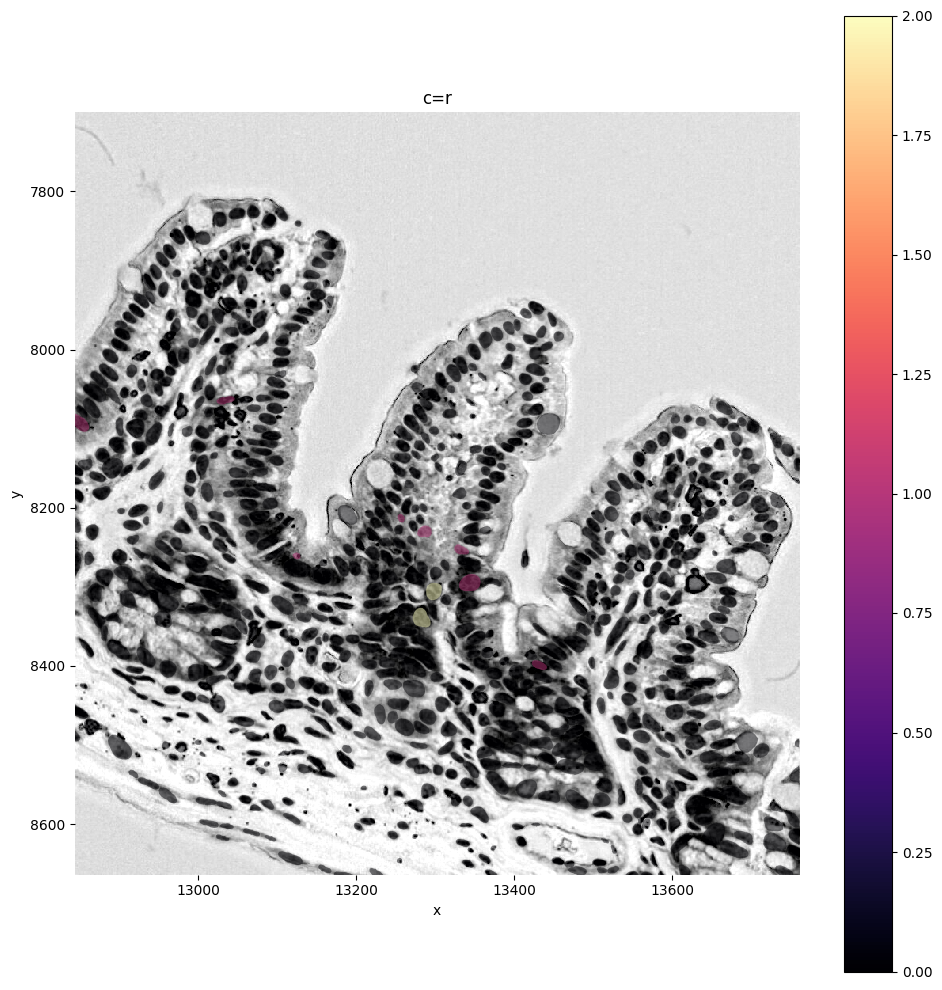

In [50]:
sp.pl.plot_shapes(
    sdata,
    img_layer = "Visium_HD_Mouse_Small_Intestine_full_image",
    shapes_layer="segmentation_boundaries", # shapes layer corresponding to labels layer
    crd = [ 12844, 13760, 7700, 8664 ],
    channel="r",
    table_layer = "table_custom_segmentation",
    column="Lypla1",
    linewidth=0,
      )